# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance
**Dataset:** Credit Card Fraud Detection (Kaggle, `creditcard.csv`)  
**Model:** Random Forest & Gradient Boosting (`HistGradientBoostingClassifier`)  
**Penanganan imbalance:** SMOTE (oversampling), Random Undersampling, dan Cost-sensitive learning (`class_weight`)

Alur: (1) import data → (2) praproses & distribusi kelas → (3) split 80:20 stratified → (4) resampling hanya pada data latih → (5) latih model tanpa vs dengan penanganan imbalance → (6) evaluasi (precision, recall, F1, AUC-ROC, AUC-PR, confusion matrix) → (7) analisis.

In [1]:
import time, warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42
os.makedirs('figures', exist_ok=True)
print('Library siap digunakan')

Library siap digunakan


## 1. Unduh dan Import Dataset
Dataset diunduh dari Kaggle dan **tidak** diunggah ke repository (>100 MB). Ubah `DATA_PATH` sesuai lokasi file di komputer/Colab Anda.

In [2]:
DATA_PATH = 'creditcard.csv'   # sesuaikan lokasi file
df = pd.read_csv(DATA_PATH)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print('Shape:', df.shape)

Shape: (284807, 31)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [5]:
print('Missing value total :', int(df.isna().sum().sum()))
print('Baris duplikat        :', int(df.duplicated().sum()))
df[['Time', 'Amount', 'Class']].describe().T

Missing value total : 0


Baris duplikat        : 1081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


## 2. Praproses Data
### 2.1 Distribusi kelas awal

            Jumlah  Persentase (%)
0 - Normal  284315         99.8273
1 - Fraud      492          0.1727

Rasio imbalance: 1 fraud : 578 normal


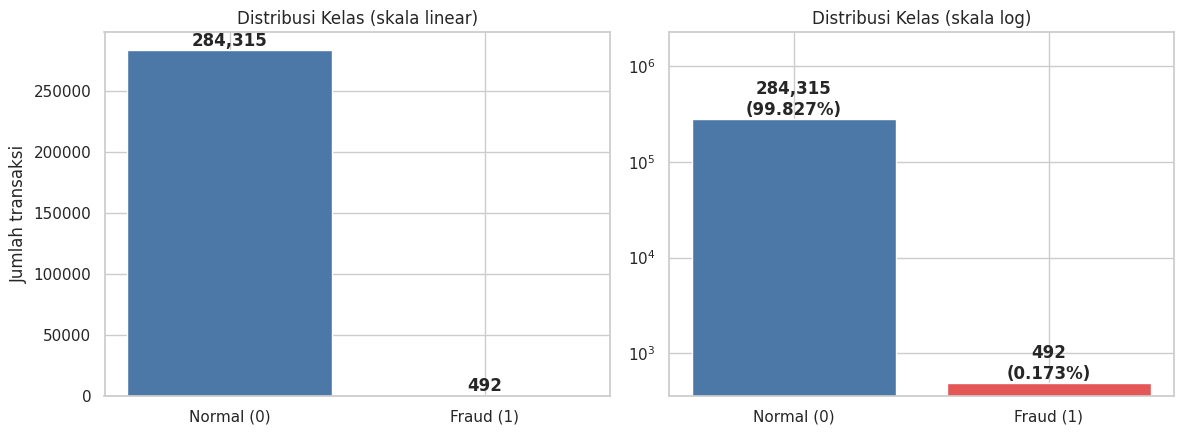

In [6]:
counts = df['Class'].value_counts().sort_index()
pct = df['Class'].value_counts(normalize=True).sort_index() * 100
dist = pd.DataFrame({'Jumlah': counts, 'Persentase (%)': pct.round(4)})
dist.index = ['0 - Normal', '1 - Fraud']
print(dist)
print(f"\nRasio imbalance: 1 fraud : {counts[0]/counts[1]:.0f} normal")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ['#4C78A8', '#E45756']
bars = ax[0].bar(['Normal (0)', 'Fraud (1)'], counts.values, color=colors)
ax[0].set_title('Distribusi Kelas (skala linear)'); ax[0].set_ylabel('Jumlah transaksi')
for b, v in zip(bars, counts.values):
    ax[0].text(b.get_x() + b.get_width()/2, v, f'{v:,}', ha='center', va='bottom', fontweight='bold')
bars = ax[1].bar(['Normal (0)', 'Fraud (1)'], counts.values, color=colors)
ax[1].set_yscale('log'); ax[1].set_title('Distribusi Kelas (skala log)')
for b, v, p in zip(bars, counts.values, pct.values):
    ax[1].text(b.get_x() + b.get_width()/2, v, f'{v:,}\n({p:.3f}%)', ha='center', va='bottom', fontweight='bold')
ax[1].set_ylim(top=counts.max()*8)
plt.tight_layout(); plt.savefig('figures/01_distribusi_kelas.png', dpi=150); plt.show()

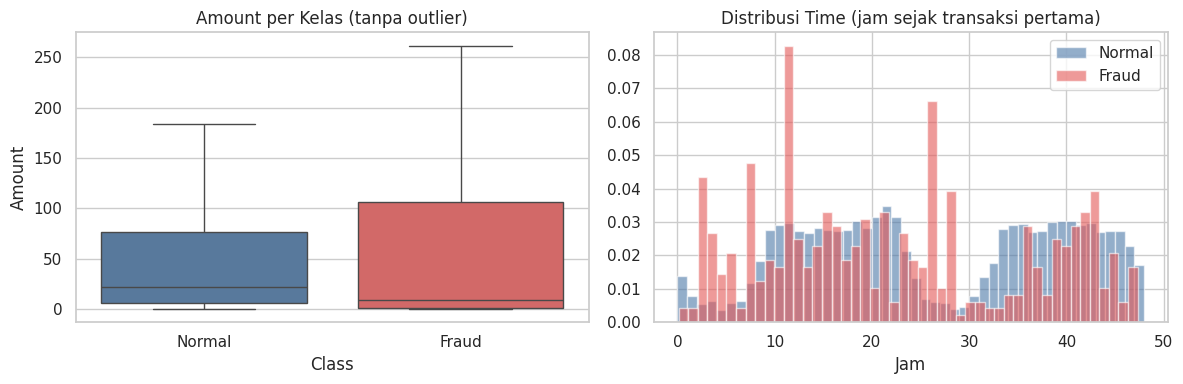

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='Class', y='Amount', ax=ax[0], showfliers=False, palette=colors)
ax[0].set_title('Amount per Kelas (tanpa outlier)'); ax[0].set_xticklabels(['Normal', 'Fraud'])
for c, col, lab in [(0, colors[0], 'Normal'), (1, colors[1], 'Fraud')]:
    ax[1].hist(df.loc[df.Class == c, 'Time']/3600, bins=48, alpha=.6, color=col, label=lab, density=True)
ax[1].set_title('Distribusi Time (jam sejak transaksi pertama)'); ax[1].set_xlabel('Jam'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/02_amount_time.png', dpi=150); plt.show()

### 2.2 Split data latih/uji 80:20 (stratified)
`stratify=y` menjaga proporsi fraud yang sama di data latih dan uji. Selanjutnya, `Time` dan `Amount` diskalakan dengan `RobustScaler` (tahan outlier) yang **di-fit hanya pada data latih** untuk mencegah *data leakage*. Fitur `V1–V28` sudah hasil PCA. Penskalaan tidak berpengaruh pada pohon keputusan, tetapi penting untuk SMOTE yang berbasis jarak k-NN.

In [8]:
X = df.drop(columns='Class')
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

scaler = RobustScaler().fit(X_train[['Time', 'Amount']])
X_train, X_test = X_train.copy(), X_test.copy()
X_train[['Time', 'Amount']] = scaler.transform(X_train[['Time', 'Amount']])
X_test[['Time', 'Amount']]  = scaler.transform(X_test[['Time', 'Amount']])

summary = pd.DataFrame({
    'Jumlah baris': [len(y_train), len(y_test)],
    'Normal': [(y_train==0).sum(), (y_test==0).sum()],
    'Fraud':  [(y_train==1).sum(), (y_test==1).sum()],
    '% Fraud': [y_train.mean()*100, y_test.mean()*100]}, index=['Train (80%)', 'Test (20%)'])
summary.round(4)

,Jumlah baris,Normal,Fraud,% Fraud
Train (80%),227845,227451,394,0.1729
Test (20%),56962,56864,98,0.1720


### 2.3 Penanganan class imbalance (hanya pada data latih)
Tiga pendekatan dibandingkan:
1. **SMOTE** – membuat sampel fraud sintetis dari interpolasi tetangga terdekat hingga rasio 1:1.
2. **Random Undersampling** – membuang sampel normal secara acak hingga rasio 1:1.
3. **Cost-sensitive learning** – tidak mengubah data, tetapi memberi bobot lebih besar pada kelas fraud (`class_weight='balanced_subsample'`).

Data uji **tidak** disentuh sehingga tetap berdistribusi asli.

SMOTE selesai dalam 0.3 detik
            Asli (train)   SMOTE  Undersampling
Normal (0)        227451  227451            394
Fraud (1)            394  227451            394


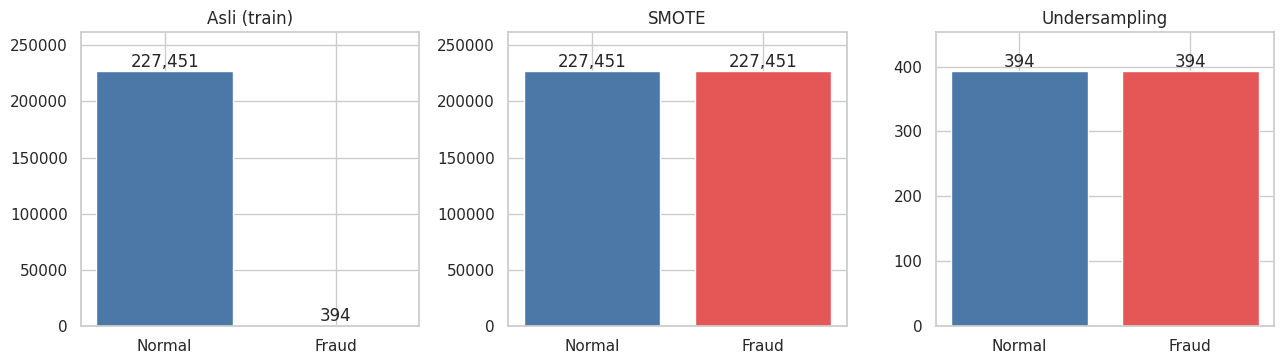

In [9]:
t0 = time.time()
X_smote, y_smote = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
print(f'SMOTE selesai dalam {time.time()-t0:.1f} detik')
X_rus, y_rus = RandomUnderSampler(random_state=RANDOM_STATE).fit_resample(X_train, y_train)

dist_tbl = pd.DataFrame({
    'Asli (train)': y_train.value_counts().sort_index(),
    'SMOTE': pd.Series(y_smote).value_counts().sort_index(),
    'Undersampling': pd.Series(y_rus).value_counts().sort_index()})
dist_tbl.index = ['Normal (0)', 'Fraud (1)']
print(dist_tbl)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for a, (name, ys) in zip(ax, [('Asli (train)', y_train), ('SMOTE', pd.Series(y_smote)), ('Undersampling', pd.Series(y_rus))]):
    vc = ys.value_counts().sort_index()
    b = a.bar(['Normal', 'Fraud'], vc.values, color=colors); a.set_title(name)
    for r, v in zip(b, vc.values): a.text(r.get_x()+r.get_width()/2, v, f'{v:,}', ha='center', va='bottom')
    a.set_ylim(0, vc.max()*1.15)
plt.tight_layout(); plt.savefig('figures/03_resampling.png', dpi=150); plt.show()

## 3. Membangun Model Klasifikasi Ensemble
Eksperimen (semua dievaluasi pada **data uji asli**, threshold 0.5):

| # | Model | Data latih |
|---|---|---|
| 1 | Random Forest | Asli (tanpa penanganan) |
| 2 | Random Forest | SMOTE |
| 3 | Random Forest | Undersampling |
| 4 | Random Forest | Asli + `class_weight` (cost-sensitive) |
| 5 | Gradient Boosting | Asli (tanpa penanganan) |
| 6 | Gradient Boosting | SMOTE |
| 7 | Gradient Boosting | Asli + `class_weight` (cost-sensitive) |

Baseline pembanding tambahan: `DummyClassifier` (selalu memprediksi normal), untuk menunjukkan jebakan accuracy.

In [10]:
results, store = [], {}

def run(name, model, Xtr, ytr):
    t0 = time.time(); model.fit(Xtr, ytr); fit_t = time.time() - t0
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results.append({'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred),
        'AUC-ROC': roc_auc_score(y_test, proba),
        'AUC-PR': average_precision_score(y_test, proba),
        'Waktu latih (s)': fit_t})
    store[name] = {'model': model, 'proba': proba, 'pred': pred, 'cm': confusion_matrix(y_test, pred)}
    r = results[-1]
    print(f"{name:<34} P={r['Precision']:.3f} R={r['Recall']:.3f} F1={r['F1-score']:.3f} ROC={r['AUC-ROC']:.4f} PR={r['AUC-PR']:.4f} ({fit_t:.0f}s)")

RF = lambda **kw: RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE, **kw)
GB = lambda **kw: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=RANDOM_STATE, **kw)

run('Dummy (selalu normal)', DummyClassifier(strategy='most_frequent'), X_train, y_train)

Dummy (selalu normal)              P=0.000 R=0.000 F1=0.000 ROC=0.5000 PR=0.0017 (0s)


In [11]:
run('RF - Tanpa penanganan', RF(), X_train, y_train)

RF - Tanpa penanganan              P=0.941 R=0.816 F1=0.874 ROC=0.9630 PR=0.8734 (233s)


In [12]:
run('RF - SMOTE', RF(), X_smote, y_smote)

RF - SMOTE                         P=0.845 R=0.837 F1=0.841 ROC=0.9734 PR=0.8706 (372s)


In [13]:
run('RF - Undersampling', RF(), X_rus, y_rus)

RF - Undersampling                 P=0.040 R=0.918 F1=0.077 ROC=0.9777 PR=0.6953 (0s)


In [14]:
run('RF - Cost-sensitive', RF(class_weight='balanced_subsample'), X_train, y_train)

RF - Cost-sensitive                P=0.960 R=0.735 F1=0.832 ROC=0.9478 PR=0.8597 (124s)


In [15]:
run('GB - Tanpa penanganan', GB(), X_train, y_train)

GB - Tanpa penanganan              P=0.503 R=0.786 F1=0.614 ROC=0.8350 PR=0.6340 (1s)


In [16]:
run('GB - SMOTE', GB(), X_smote, y_smote)

GB - SMOTE                         P=0.703 R=0.847 F1=0.769 ROC=0.9374 PR=0.7702 (22s)


In [17]:
run('GB - Cost-sensitive', GB(class_weight='balanced'), X_train, y_train)

GB - Cost-sensitive                P=0.330 R=0.888 F1=0.481 ROC=0.9677 PR=0.7277 (2s)


## 4. Evaluasi Model

In [18]:
res = pd.DataFrame(results).set_index('Model')
res.to_csv('hasil_evaluasi.csv')
res.style.format({c: '{:.4f}' for c in res.columns if c != 'Waktu latih (s)'} | {'Waktu latih (s)': '{:.1f}'}) \
   .background_gradient(cmap='Greens', subset=['Precision', 'Recall', 'F1-score', 'AUC-ROC', 'AUC-PR'])

,Accuracy,Precision,Recall,F1-score,AUC-ROC,AUC-PR,Waktu latih (s)
Model,,,,,,,
Dummy (selalu normal),0.9983,0.0000,0.0000,0.0000,0.5000,0.0017,0.0
RF - Tanpa penanganan,0.9996,0.9412,0.8163,0.8743,0.9630,0.8734,232.6
RF - SMOTE,0.9995,0.8454,0.8367,0.8410,0.9734,0.8706,372.1
RF - Undersampling,0.9622,0.0402,0.9184,0.0771,0.9777,0.6953,0.3
RF - Cost-sensitive,0.9995,0.9600,0.7347,0.8324,0.9478,0.8597,124.2
GB - Tanpa penanganan,0.9983,0.5033,0.7857,0.6135,0.8350,0.6340,1.4
GB - SMOTE,0.9991,0.7034,0.8469,0.7685,0.9374,0.7702,21.6
GB - Cost-sensitive,0.9967,0.3295,0.8878,0.4807,0.9677,0.7277,2.3


### 4.1 Perbandingan metrik pada kelas minoritas (fraud)

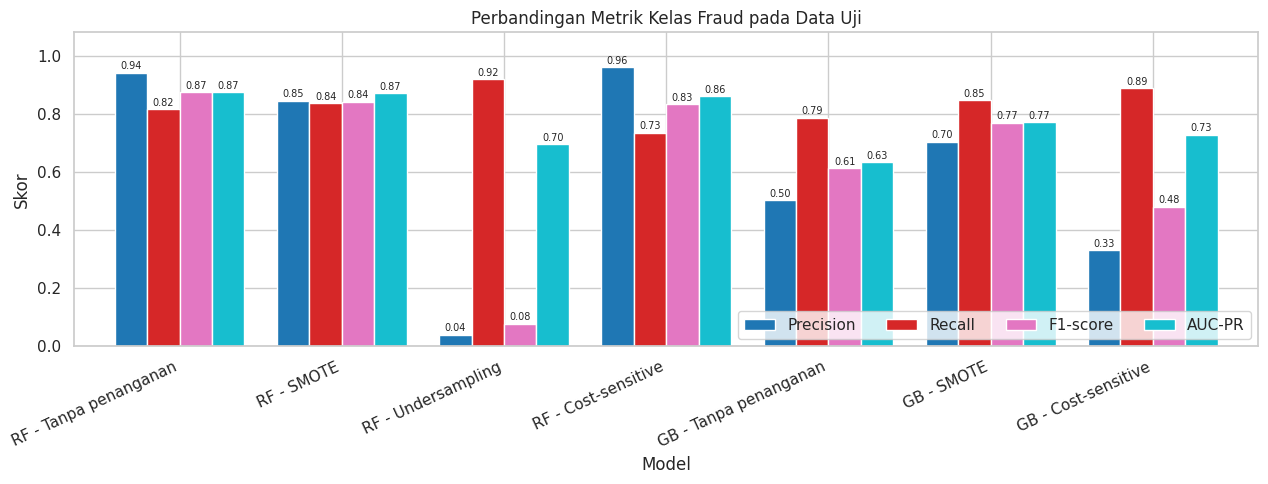

In [19]:
plot_df = res.drop(index='Dummy (selalu normal)')[['Precision', 'Recall', 'F1-score', 'AUC-PR']]
ax = plot_df.plot(kind='bar', figsize=(13, 5), width=.8, colormap='tab10')
ax.set_title('Perbandingan Metrik Kelas Fraud pada Data Uji'); ax.set_ylabel('Skor'); ax.set_ylim(0, 1.08)
plt.xticks(rotation=25, ha='right'); plt.legend(loc='lower right', ncol=4)
for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=7, padding=1)
plt.tight_layout(); plt.savefig('figures/04_perbandingan_metrik.png', dpi=150); plt.show()

### 4.2 Confusion matrix

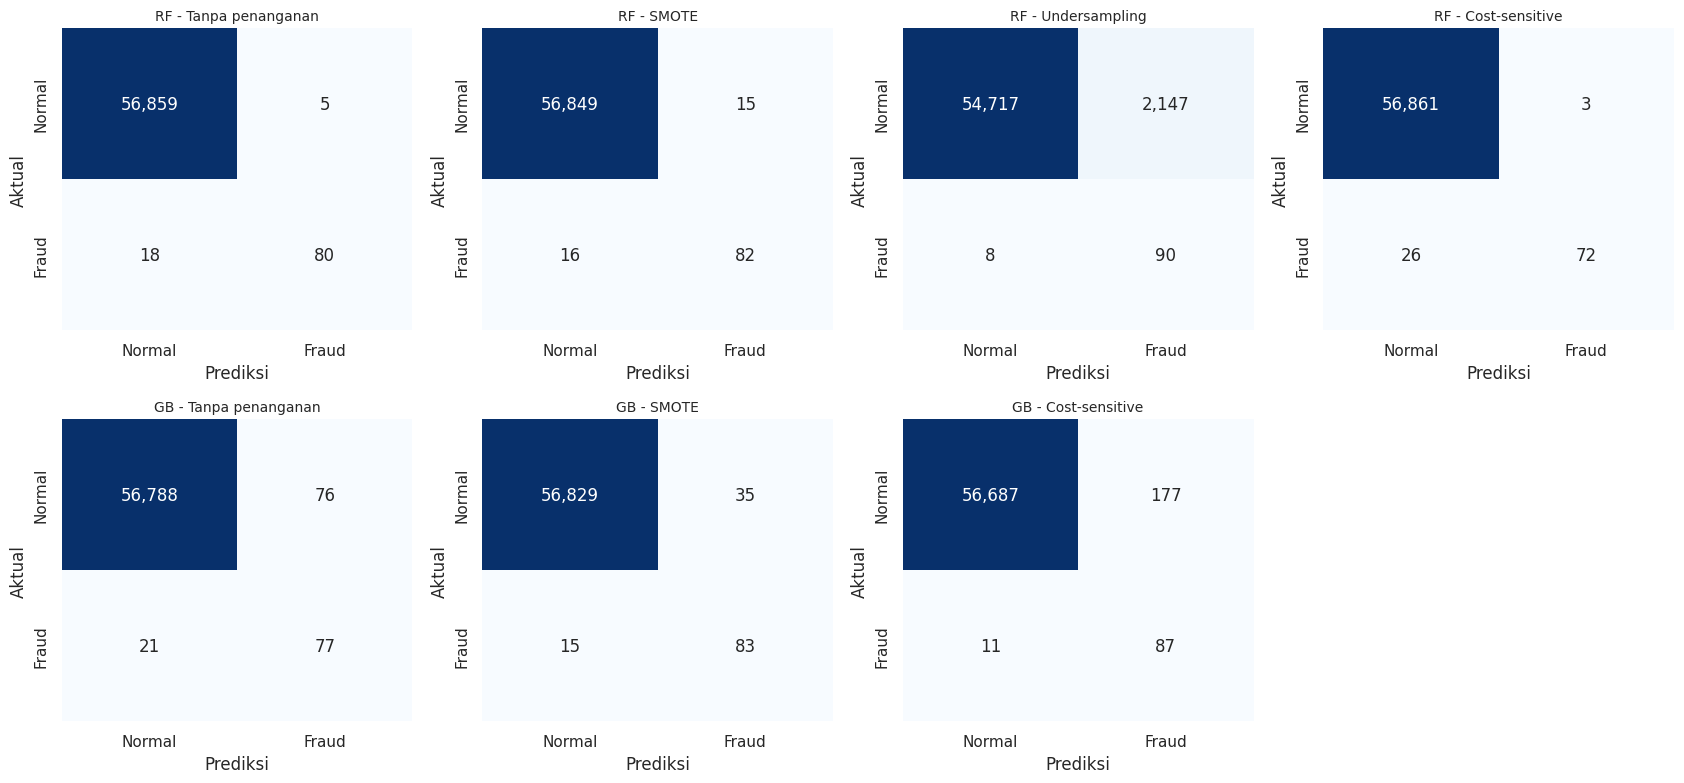

In [20]:
names = [n for n in store if not n.startswith('Dummy')]
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, n in zip(axes.ravel(), names):
    cm = store[n]['cm']
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])
    ax.set_title(n, fontsize=10); ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.savefig('figures/05_confusion_matrix.png', dpi=150); plt.show()

### 4.3 Kurva ROC dan Precision-Recall

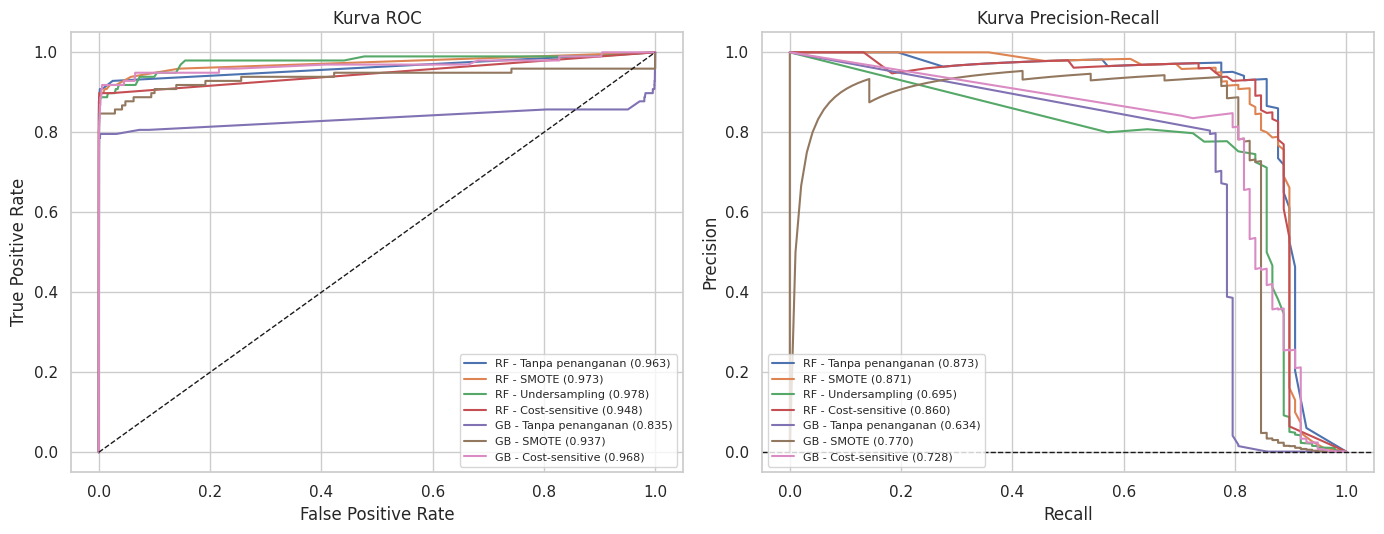

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for n in names:
    fpr, tpr, _ = roc_curve(y_test, store[n]['proba'])
    ax[0].plot(fpr, tpr, label=f"{n} ({res.loc[n,'AUC-ROC']:.3f})")
    p, r, _ = precision_recall_curve(y_test, store[n]['proba'])
    ax[1].plot(r, p, label=f"{n} ({res.loc[n,'AUC-PR']:.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_title('Kurva ROC'); ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate'); ax[0].legend(fontsize=8, loc='lower right')
ax[1].axhline(y_test.mean(), color='k', ls='--', lw=1); ax[1].set_title('Kurva Precision-Recall'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig('figures/06_roc_pr.png', dpi=150); plt.show()

### 4.4 Mengapa accuracy saja tidak cukup?
Fraud hanya ~0,17% dari seluruh transaksi. Model "bodoh" yang selalu menebak *normal* sudah mendapat accuracy sangat tinggi, tetapi tidak mendeteksi satu pun fraud.

                       Accuracy  Precision  Recall  F1-score  AUC-ROC
Model                                                                
Dummy (selalu normal)    0.9983     0.0000  0.0000    0.0000   0.5000
RF - Tanpa penanganan    0.9996     0.9412  0.8163    0.8743   0.9630
RF - SMOTE               0.9995     0.8454  0.8367    0.8410   0.9734

Dummy: accuracy 99.83% tetapi 0 dari 98 fraud terdeteksi (recall = 0).


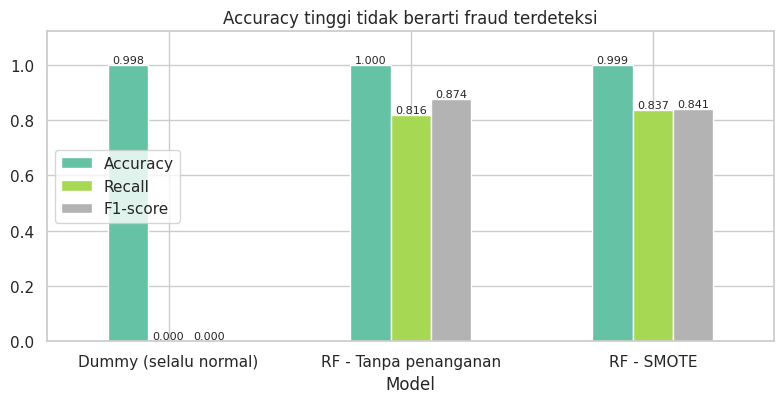

In [22]:
cols = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUC-ROC']
cmp = res.loc[['Dummy (selalu normal)', 'RF - Tanpa penanganan', 'RF - SMOTE'], cols]
print(cmp.round(4).to_string())
cm = store['Dummy (selalu normal)']['cm']
print(f"\nDummy: accuracy {res.loc['Dummy (selalu normal)','Accuracy']*100:.2f}% tetapi {cm[1,1]} dari {cm[1].sum()} fraud terdeteksi (recall = 0).")

fig, ax = plt.subplots(figsize=(8, 4.2))
sel = res.loc[['Dummy (selalu normal)', 'RF - Tanpa penanganan', 'RF - SMOTE'], ['Accuracy', 'Recall', 'F1-score']]
sel.plot(kind='bar', ax=ax, colormap='Set2'); ax.set_ylim(0, 1.12); plt.xticks(rotation=0)
for c in ax.containers: ax.bar_label(c, fmt='%.3f', fontsize=8)
ax.set_title('Accuracy tinggi tidak berarti fraud terdeteksi'); plt.tight_layout()
plt.savefig('figures/07_accuracy_trap.png', dpi=150); plt.show()

### 4.5 Laporan klasifikasi rinci & feature importance

In [23]:
best = res.drop(index='Dummy (selalu normal)')['F1-score'].idxmax()
print('Model dengan F1-score fraud tertinggi:', best, '\n')
print(classification_report(y_test, store[best]['pred'], target_names=['Normal', 'Fraud'], digits=4))

Model dengan F1-score fraud tertinggi: RF - Tanpa penanganan 

              precision    recall  f1-score   support

      Normal     0.9997    0.9999    0.9998     56864
       Fraud     0.9412    0.8163    0.8743        98

    accuracy                         0.9996     56962
   macro avg     0.9704    0.9081    0.9371     56962
weighted avg     0.9996    0.9996    0.9996     56962



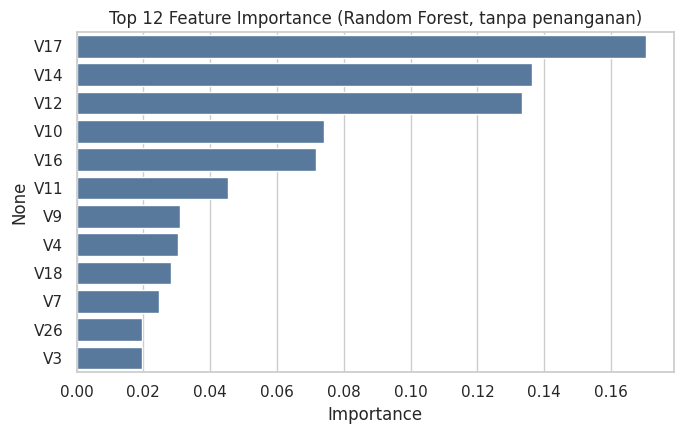

In [24]:
rf_name = 'RF - SMOTE' if 'RF - SMOTE' in store else best
imp = pd.Series(store['RF - Tanpa penanganan']['model'].feature_importances_, index=X_train.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(7, 4.5)); sns.barplot(x=imp.values, y=imp.index, color='#4C78A8')
plt.title('Top 12 Feature Importance (Random Forest, tanpa penanganan)'); plt.xlabel('Importance')
plt.tight_layout(); plt.savefig('figures/08_feature_importance.png', dpi=150); plt.show()

## 5. Analisis dan Kesimpulan

**Distribusi kelas.** Dari 284.807 transaksi hanya 492 (0,1727%) yang fraud, rasio ±1 : 578. Data uji (20%) berisi 56.962 transaksi dengan **98 fraud**.

**Hasil perbandingan (data uji asli, threshold 0,5):**

| Model | Precision | Recall | F1 | AUC-ROC | AUC-PR | FP | FN |
|---|---|---|---|---|---|---|---|
| RF – tanpa penanganan | 0,941 | 0,816 | **0,874** | 0,963 | **0,873** | 5 | 18 |
| RF – SMOTE | 0,845 | 0,837 | 0,841 | 0,973 | 0,871 | 15 | 16 |
| RF – Undersampling | 0,040 | 0,918 | 0,077 | **0,978** | 0,695 | 2.147 | 8 |
| RF – Cost-sensitive | 0,960 | 0,735 | 0,832 | 0,948 | 0,860 | 3 | 26 |
| GB – tanpa penanganan | 0,503 | 0,786 | 0,614 | 0,835 | 0,634 | 76 | 21 |
| GB – SMOTE | 0,703 | 0,847 | 0,769 | 0,937 | 0,770 | 35 | 15 |
| GB – Cost-sensitive | 0,330 | 0,888 | 0,481 | 0,968 | 0,728 | 177 | 11 |

**Interpretasi**
1. **Accuracy menyesatkan.** Model dummy yang selalu menebak "normal" memperoleh accuracy 99,83% tetapi recall 0 (tidak satu pun fraud terdeteksi). Karena itu evaluasi memakai precision, recall, F1, AUC-ROC, dan AUC-PR pada kelas fraud.
2. **Penanganan imbalance menggeser trade-off precision–recall.** Pada Random Forest, SMOTE menaikkan recall (0,816 → 0,837) dan AUC-ROC (0,963 → 0,973) tetapi menurunkan precision (0,941 → 0,845) karena lebih banyak false positive (5 → 15). Undersampling memberi recall tertinggi (0,918) namun membuang 99,8% data normal sehingga precision hanya 0,040 (2.147 false positive), sehingga tidak praktis. Cost-sensitive learning menggeser model ke arah precision (0,960) dengan recall lebih rendah (0,735).
3. **Pada Gradient Boosting, penanganan imbalance jelas membantu.** SMOTE menaikkan F1 dari 0,614 menjadi 0,769 dan AUC-PR dari 0,634 menjadi 0,770. Cost-sensitive menaikkan recall (0,888) dengan biaya precision (0,330).
4. **Random Forest tanpa penanganan sudah sangat kuat.** Ia memberi F1 dan AUC-PR tertinggi pada threshold 0,5. Ini bukan berarti penanganan imbalance tidak berguna: SMOTE/undersampling/class weight mengubah *titik operasi* model, dan pilihan terbaik bergantung pada biaya bisnis (fraud lolos vs. transaksi sah yang diblokir).
5. **Catatan kehati-hatian.** Data uji hanya memuat 98 fraud, sehingga selisih 1–2 deteksi mengubah recall ±1–2 poin. Perbedaan kecil antar model RF (mis. SMOTE vs. tanpa penanganan) berada dalam ketidakpastian satu kali split. Validasi silang berstrata atau pengulangan dengan seed berbeda akan memberi kesimpulan lebih kokoh. Resampling dilakukan hanya pada data latih sehingga tidak ada kebocoran data ke data uji.
6. **Fitur penting.** Fitur hasil PCA tertentu (V17, V14, V12, V10, dan V16 secara berurutan) paling berpengaruh pada pemisahan fraud (lihat Feature Importance).

**Kesimpulan:** Ensemble method sangat efektif untuk deteksi fraud. Untuk Random Forest, SMOTE memberi keseimbangan precision–recall yang wajar dan AUC-ROC tertinggi di antara varian yang layak dipakai, sedangkan untuk Gradient Boosting, SMOTE meningkatkan semua metrik fraud secara nyata. Evaluasi harus selalu memakai metrik kelas minoritas, bukan accuracy.